In [2]:
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt

In [3]:
data=pd.read_csv("/content/iris.csv")
data

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


Data inspection


In [4]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [5]:
for i in data.select_dtypes(include='object'):
    print(data[i].value_counts())
    print('\n')

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64




Exploratory data analysis

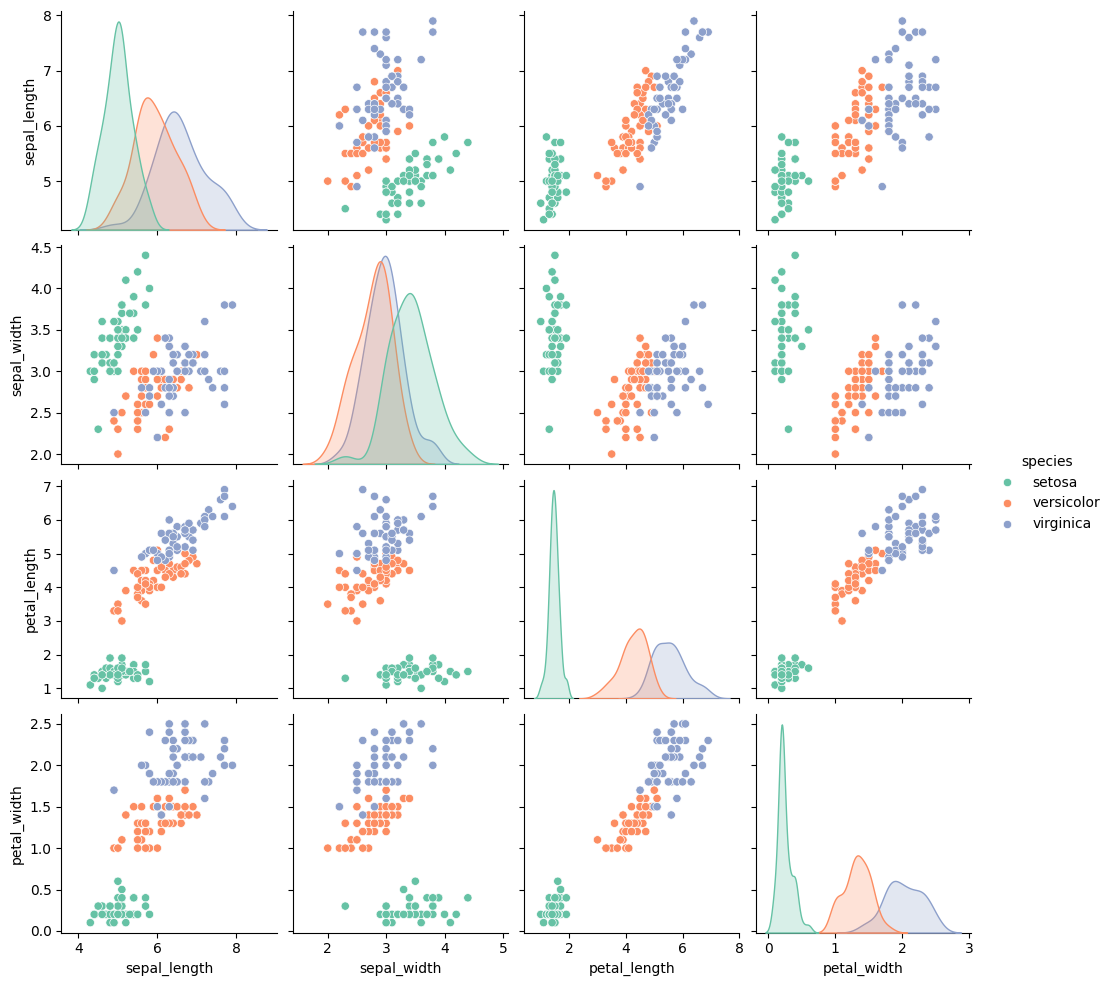

In [8]:
sn.pairplot(data, hue="species", diag_kind="kde", palette="Set2")
plt.show()

Standard scaler


In [10]:
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [12]:
x=data.drop(columns=["species"])
y=data["species"]

In [21]:
#Normalize features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

#Encode target labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)



In [35]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

Splitting dataset

In [22]:
x_train, x_test, y_train, y_test = train_test_split(
    x_scaled, y_encoded, test_size=0.2, random_state=42)


Logistic Regression

In [23]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(x_train, y_train)
y_pred_log = log_reg.predict(x_test)

Decision Tree

In [24]:
dt= DecisionTreeClassifier(random_state=42)
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)

Evaluate both models

In [25]:
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nLogistic Regression Report:\n", classification_report(y_test, y_pred_log, target_names=encoder.classes_))
print("\nDecision Tree Report:\n", classification_report(y_test, y_pred_dt, target_names=encoder.classes_))

Logistic Regression Accuracy: 1.0
Decision Tree Accuracy: 1.0

Logistic Regression Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Decision Tree Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Confusion Matrix Heatmap

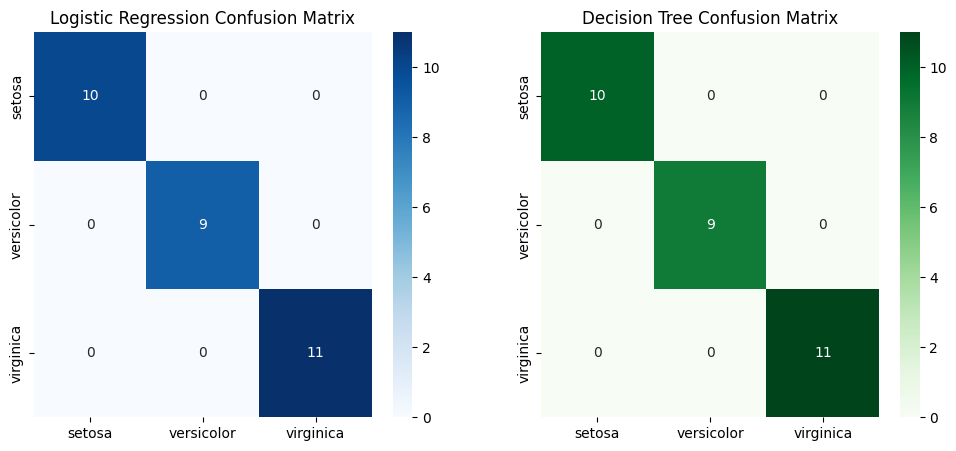

In [29]:
cm_log = confusion_matrix(y_test, y_pred_log)
cm_dt = confusion_matrix(y_test, y_pred_dt)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sn.heatmap(cm_log, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)
axes[0].set_title("Logistic Regression Confusion Matrix")

sn.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=encoder.classes_, yticklabels=encoder.classes_)
axes[1].set_title("Decision Tree Confusion Matrix")

plt.show()

Decision Boundary

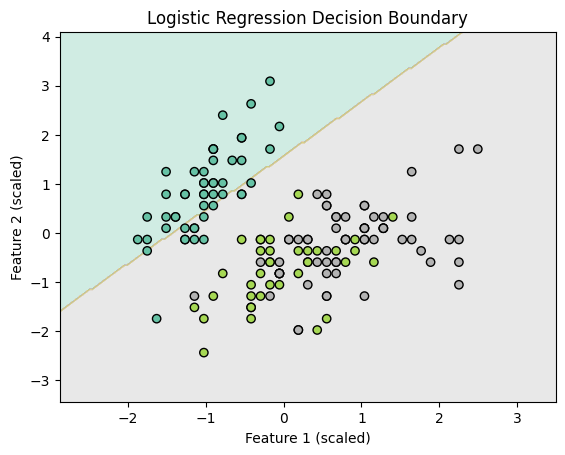

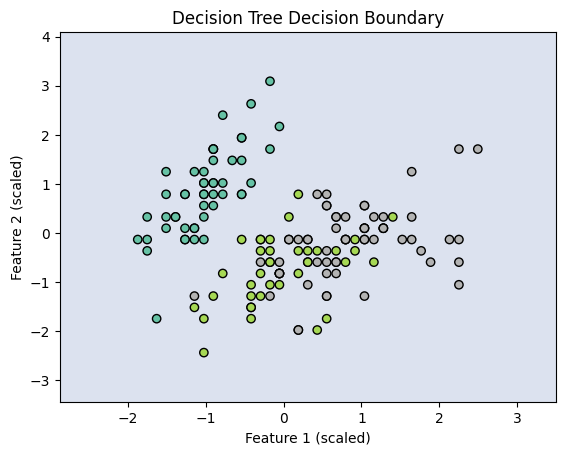

In [38]:
def plot_decision_boundary(model, x, y, title):
    # Only use first two features for visualization
    x_plot = x[:, :2]
    x_min, x_max = x_plot[:, 0].min() - 1, x_plot[:, 0].max() + 1
    y_min, y_max = x_plot[:, 1].min() - 1, x_plot[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel(),
                            np.zeros((xx.ravel().shape[0], x.shape[1]-2))])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set2)
    plt.scatter(x_plot[:, 0], x_plot[:, 1], c=y, edgecolor="k", cmap=plt.cm.Set2)
    plt.title(title)
    plt.xlabel("Feature 1 (scaled)")
    plt.ylabel("Feature 2 (scaled)")
    plt.show()

  # Plot decision boundaries
plot_decision_boundary(log_reg, x_scaled, y_encoded, "Logistic Regression Decision Boundary")
plot_decision_boundary(dt, x_scaled, y_encoded, "Decision Tree Decision Boundary")